# 시계열 Flow Matching의 예측별 샘플링 예산

**연구 질문**　같은 평균 네트워크 평가 횟수(NFE)에서, 하루 합계와 급변 확률의 수치 오차에 따라 계산을 배분하면 시계열 확률 예측의 품질을 높일 수 있는가?

리만 가설 해설에서 가중 소수 합의 오차를 변환해 영점의 기여를 읽듯, 이 실험은 공분산을 고유모드로 바꿔 유한 스텝 샘플링의 오차를 계산한다. 이어 정답을 아는 분포와 보류한 실측 데이터에서 서로 다른 주장을 검증한다. 아래 수치 결과는 **정확한 벡터장을 입력한 합성 실험**에서 얻었다. 신경망 학습과 실측 시계열 평가는 연구계획에 포함돼 있다. [리만 가설 해설 §I.1](https://www.math.uwaterloo.ca/~mrubinst/alpoge_claude_grh/zeta-paper.pdf#page=4)

Python 3.10 이상과 NumPy, SciPy, Matplotlib을 갖춘 Jupyter 환경에서 위에서 아래로 실행한다. 입력 데이터는 식으로 생성한다.

| 관련 연구 | 이번 연구에서 확인할 점 |
|---|---|
| TSFlow (ICLR 2025) | 동일한 CFM 체크포인트에서 예산 배분이 주는 효과를 먼저 측정한다. 독립 prior와 GP prior의 결과를 함께 보고한다. [논문](https://proceedings.iclr.cc/paper_files/paper/2025/file/ee1a1ecc92f35702b5c29dad3dc909ea-Paper-Conference.pdf) |
| PathFM (2026 프리프린트) | 이미 1~2회 샘플링, 전체 예측 경로, Sum CRPS를 다룬다. 공통 과제의 경로 품질과 실제 지연시간을 비교하는 외부 기준이다. [논문](https://arxiv.org/abs/2610.22358) |
| AREX, Correcting CondOT (2026 프리프린트) | 이미 가우시안 성분의 해석적 적분과 유한 스텝 가우시안 분석을 다룬다. 가우시안 정답 계산은 기전 검증에 사용한다. [AREX](https://arxiv.org/abs/2610.03483) · [Correcting CondOT](https://arxiv.org/abs/2609.39488) |
| FlowBudget, INDIS, TrajCal | 이미 샘플링 예산 추정, 입력별 격자, 보정 데이터로 맞춘 고정 격자가 연구됐다. 후보 기여는 **합계와 급변에 민감한 예측별 배분이 전체 경로 오차에 따른 배분을 이기는 조건**이다. [FlowBudget](https://arxiv.org/abs/2610.20636) · [INDIS](https://openaccess.thecvf.com/content/CVPR2026/papers/Yuan_Few-Step_Diffusion_Sampling_Through_Instance-Aware_Discretizations_CVPR_2026_paper.pdf) · [TrajCal](https://arxiv.org/abs/2611.25847) |

## 1. 정확한 CFM에서 24시간 합계 분산을 검증한다

가정은 양의 정부호 공분산 \(K_0,K_\star\), 독립 끝점, 선형 경로 \(X_t=(1-t)X_0+tX_1\), 정확한 벡터장, 명시적 Euler다. 예측의 조건을 하나 고정한다. 평균은 선형으로 이동하므로 공분산 계산에선 중심화할 수 있다. Gaussian CFM에서 \(C_t=(1-t)^2 K_0+t^2K_\star\), 벡터장은 \(\big(tK_\star-(1-t)K_0\big)C_t^{-1}x\)이다. [Gaussian flow-matching field, Proposition 3.2](https://epubs.siam.org/doi/10.1137/25M1803966)

시작 분포를 \(K_0^{-1/2}\)로 백색화하고, \(K_0^{-1/2}K_\star K_0^{-1/2}\)의 고유값을 \(\lambda_i\)라 하자. 한 모드의 표준편차 경로는 \(f_i(t)=\sqrt{(1-t)^2+\lambda_i t^2}\)다. 정확한 한 스텝의 배율은 \(f_i(t+h)/f_i(t)\)이고, Euler 배율은 \(1+h f_i'(t)/f_i(t)\)다. 이 둘의 비는 벡터 \((1-t,\sqrt{\lambda_i}t)\)와 \((1-t-h,\sqrt{\lambda_i}(t+h))\) 사이 각의 코사인이다. 따라서 \(\theta_i(t)=\operatorname{atan2}(\sqrt{\lambda_i}t,1-t)\)로 두면

\[
\frac{\widehat\lambda_{i,N}}{\lambda_i}=\prod_{j=0}^{N-1}\cos^2\bigl(\theta_i(t_{j+1})-\theta_i(t_j)\bigr).
\]

각도 증가량의 합은 \(\pi/2\)다. \(\log\cos\)의 오목성을 쓰면 \(N\ge2\)에서 모드별 분산 비가 \(\cos^{2N}(\pi/(2N))\) 이하라는 검산 기준도 얻는다. 따라서 이 설정에서는 모든 선형 합 \(a^\top Y\)의 분산을 Euler가 과소평가한다. 이 결론의 가정에는 적분법과 끝점 짝짓기가 포함된다. Minibatch OT coupling은 별도 실험으로 다룬다.

파일럿은 분산 1, 자기회귀계수 0.8인 AR(1)을 마지막 관측값 0에 조건부로 사용한다. 24시간 정답 공분산은 \(K_{\star,hk}=\rho^{|h-k|}-\rho^{h+k}\), 독립 prior는 \(K_0=\operatorname{diag}(K_\star)\)다. 고유모드 공식과 좌표계에서 직접 수행한 행렬 Euler를 대조한다.

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
from scipy.linalg import eigh
from scipy.optimize import brentq
from scipy.special import expit, ndtr, ndtri

rho = 0.8
horizon = 24
nfe_grid = (4, 8, 16, 64)
hours = np.arange(1, horizon + 1)
target = rho ** np.abs(hours[:, None] - hours) - rho ** (hours[:, None] + hours)
prior = np.diag(np.diag(target))
prior_scale = np.sqrt(np.diag(prior))
eigenvalues, basis = eigh(target / np.outer(prior_scale, prior_scale))
total = np.ones(horizon)
projected_modes = basis.T @ (prior_scale * total)
total_variance = total @ target @ total
central_quantile = ndtri(0.95)

def gaussian_drift(time):
    denominator = (1 - time) ** 2 + time**2 * eigenvalues
    return (time * eigenvalues - (1 - time)) / denominator

gaussian_results = []
print(f"True 24-hour sum SD: {np.sqrt(total_variance):.6f}")
print("NFE | Euler variance / truth | Euler coverage | Heun coverage")
for nfe in nfe_grid:
    grid = np.linspace(0, 1, nfe + 1)
    angles = np.arctan2(grid[:, None] * np.sqrt(eigenvalues), 1 - grid[:, None])
    eigenvalue_ratios = np.prod(np.cos(np.diff(angles, axis=0)) ** 2, axis=0)
    upper_bound = np.cos(np.pi / (2 * nfe)) ** (2 * nfe)
    assert np.all(eigenvalue_ratios <= upper_bound + 1e-12)

    expected_variance = (projected_modes**2) @ (eigenvalues * eigenvalue_ratios)
    operator = np.eye(horizon)
    for time in grid[:-1]:
        covariance_path = (1 - time) ** 2 * prior + time**2 * target
        cross_covariance = time * target - (1 - time) * prior
        drift = np.linalg.solve(covariance_path, cross_covariance.T).T
        operator = (np.eye(horizon) + drift / nfe) @ operator
    euler_covariance = operator @ prior @ operator.T
    assert np.isclose(total @ euler_covariance @ total, expected_variance, rtol=1e-12)
    assert eigh(target - euler_covariance, eigvals_only=True).min() > 0

    heun_scale = np.ones(horizon)
    heun_grid = grid[::2]  # Two network calls per Heun step.
    for start, end in zip(heun_grid[:-1], heun_grid[1:]):
        step = end - start
        drift_start, drift_end = gaussian_drift(start), gaussian_drift(end)
        heun_scale *= 1 + step * (drift_start + drift_end * (1 + step * drift_start)) / 2
    euler_ratio = expected_variance / total_variance

    # The standardized source has unit variance in each mode.
    # The squared Heun multiplier is already the terminal modal variance.
    heun_variance = (projected_modes**2) @ (heun_scale**2)
    heun_ratio = heun_variance / total_variance
    heun_operator = np.eye(horizon)
    identity = np.eye(horizon)
    for start, end in zip(heun_grid[:-1], heun_grid[1:]):
        matrix_fields = []
        for time in (start, end):
            covariance_path = (1 - time)**2 * prior + time**2 * target
            cross_covariance = time * target - (1 - time) * prior
            matrix_fields.append(np.linalg.solve(covariance_path, cross_covariance.T).T)
        matrix_start, matrix_end = matrix_fields
        step = end - start
        predictor = identity + step * matrix_start
        heun_operator = (identity + step * (matrix_start + matrix_end @ predictor) / 2) @ heun_operator
    direct_heun_covariance = heun_operator @ prior @ heun_operator.T
    np.testing.assert_allclose(heun_variance, total @ direct_heun_covariance @ total, rtol=1e-12)
    euler_coverage = 2 * ndtr(central_quantile * np.sqrt(euler_ratio)) - 1
    heun_coverage = 2 * ndtr(central_quantile * np.sqrt(heun_ratio)) - 1
    gaussian_results.append((nfe, euler_ratio, euler_coverage, heun_coverage))
    print(f"{nfe:3d} | {euler_ratio:8.3%} | {euler_coverage:8.3%} | {heun_coverage:8.3%}")

True 24-hour sum SD: 12.662530
NFE | Euler variance / truth | Euler coverage | Heun coverage
  4 |  40.342% |  70.386% |  70.214%
  8 |  64.865% |  81.474% |  86.881%
 16 |  80.712% |  86.052% |  89.381%
 64 |  94.799% |  89.074% |  89.968%


## 2. 평균과 공분산이 같아도 어려운 예측이 생기는지 확인한다

표준화한 합계의 참분포로 정규분포와 두 성분 혼합을 만든다. \(S\sim\mathrm{Bernoulli}(q)\), \(Z\sim N(0,1)\)을 독립으로 두고

\[
M_\nu=\sqrt{\frac{\nu}{q(1-q)}}(S-q)+\sqrt{1-\nu}\,Z,\qquad 0\le\nu<1.
\]

두 성분을 섞어도 평균은 0, 분산은 1이다. \(q=0.1\)과 \(\nu=0.8\)을 예시로 사용한다. 24차원 실험에선 이 분포를 \(K_\star^{1/2}a\)에 평행한 백색화 좌표 한 축에 놓고, 직교 방향을 표준 가우시안으로 두면 전체 평균과 공분산을 유지한 채 \(a^\top Y\)의 꼬리를 바꿀 수 있다.

아래에서는 1차원 합계 축을 직접 검증한다. 보간 시각의 밀도가 가우시안 혼합이므로, 정확한 속도는 각 성분의 가우시안 속도를 사후 성분 확률로 가중한 값이다. 모멘트를 맞춘 가우시안 부분은 닫힌형으로 처리하고 잔차를 Heun으로 적분한다. 혼합 CDF의 수치 역함수와 고정밀 ODE를 대조하고, 고정 배분과 **상태를 이미 아는 오라클 배분**을 비교한다. 후자는 배분 이득의 가능성을 확인하는 대조다.

In [2]:
rare_probability = 0.1
threshold = ndtri(0.95)
quantile_levels = (np.arange(16384) + 0.5) / 16384
initial_quantiles = ndtri(quantile_levels)

def mixture_parameters(fraction):
    shift = np.sqrt(fraction / (rare_probability * (1 - rare_probability)))
    common_mean = -shift * rare_probability
    rare_mean = shift * (1 - rare_probability)
    component_variance = 1 - fraction
    np.testing.assert_allclose((1 - rare_probability) * common_mean + rare_probability * rare_mean, 0, atol=1e-12)
    np.testing.assert_allclose(
        component_variance + (1 - rare_probability) * common_mean**2 + rare_probability * rare_mean**2, 1
    )
    return common_mean, rare_mean, component_variance

def mixture_cdf(value, parameters):
    common_mean, rare_mean, variance = parameters
    scale = np.sqrt(variance)
    return (1 - rare_probability) * ndtr((value - common_mean) / scale) + rare_probability * ndtr((value - rare_mean) / scale)

def residual_drift(time, coordinate, parameters):
    common_mean, rare_mean, variance = parameters
    reference_variance = (1 - time) ** 2 + time**2
    reference_scale = np.sqrt(reference_variance)
    physical_state = reference_scale * coordinate
    component_variance = (1 - time) ** 2 + time**2 * variance
    log_odds = np.log(rare_probability / (1 - rare_probability))
    log_odds += (
        2 * physical_state * time * (rare_mean - common_mean)
        + time**2 * (common_mean**2 - rare_mean**2)
    ) / (2 * component_variance)
    posterior_mean = common_mean + (rare_mean - common_mean) * expit(log_odds)
    affine_coefficient = (time * variance - (1 - time)) / component_variance
    full_drift = affine_coefficient * physical_state + (1 - time) * posterior_mean / component_variance
    return full_drift / reference_scale - (2 * time - 1) * coordinate / reference_variance

def integrate_residual(coordinate, parameters, nfe):
    assert nfe >= 2 and nfe % 2 == 0
    steps = nfe // 2
    width = 1 / steps
    for index in range(steps):
        time = index * width
        first = residual_drift(time, coordinate, parameters)
        second = residual_drift(time + width, coordinate + width * first, parameters)
        coordinate = coordinate + width * (first + second) / 2
    return coordinate

mixture_results = {}
for fraction in (0.0, 0.6, 0.8, 0.9):
    parameters = mixture_parameters(fraction)
    low = np.full_like(quantile_levels, -16.0)
    high = -low
    for _ in range(54):
        midpoint = (low + high) / 2
        below = mixture_cdf(midpoint, parameters) < quantile_levels
        low = np.where(below, midpoint, low)
        high = np.where(below, high, midpoint)
    true_quantiles = (low + high) / 2
    numerical_reference = solve_ivp(
        lambda time, coordinate: residual_drift(time, coordinate, parameters),
        (0.0, 1.0), initial_quantiles[::128], rtol=1e-11, atol=1e-12,
    )
    assert numerical_reference.success
    np.testing.assert_allclose(numerical_reference.y[:, -1], true_quantiles[::128], rtol=0, atol=1e-7)
    true_tail = 1 - mixture_cdf(threshold, parameters)

    for nfe in (4, 8, 12, 16, 32, 64):
        approximate_quantiles = integrate_residual(initial_quantiles, parameters, nfe)
        assert np.all(np.diff(approximate_quantiles) > 0)
        cutoff = brentq(lambda value: integrate_residual(value, parameters, nfe) - threshold, -10, 10)
        predicted_tail = 1 - ndtr(cutoff)
        wasserstein = np.mean(np.abs(approximate_quantiles - true_quantiles))
        mixture_results[fraction, nfe] = (true_tail, predicted_tail, wasserstein)

print("Equal weights for the Gaussian and nu=0.8 mixture contexts")
print("Allocation (Gaussian, mixture) | average NFE | mixture true tail | mixture predicted tail | mean W1")
for gaussian_nfe, mixture_nfe in ((8, 8), (4, 12), (12, 4)):
    true_tail, predicted_tail, mixture_w1 = mixture_results[0.8, mixture_nfe]
    gaussian_w1 = mixture_results[0.0, gaussian_nfe][2]
    print(
        f"({gaussian_nfe:2d}, {mixture_nfe:2d}) | {(gaussian_nfe + mixture_nfe) / 2:4.1f}"
        f" | {true_tail:.4%} | {predicted_tail:.4%} | {(mixture_w1 + gaussian_w1) / 2:.6f}"
    )

Equal weights for the Gaussian and nu=0.8 mixture contexts
Allocation (Gaussian, mixture) | average NFE | mixture true tail | mixture predicted tail | mean W1
( 8,  8) |  8.0 | 9.8995% | 9.7051% | 0.004242
( 4, 12) |  8.0 | 9.8995% | 9.8170% | 0.003283
(12,  4) |  8.0 | 9.8995% | 8.6322% | 0.035431


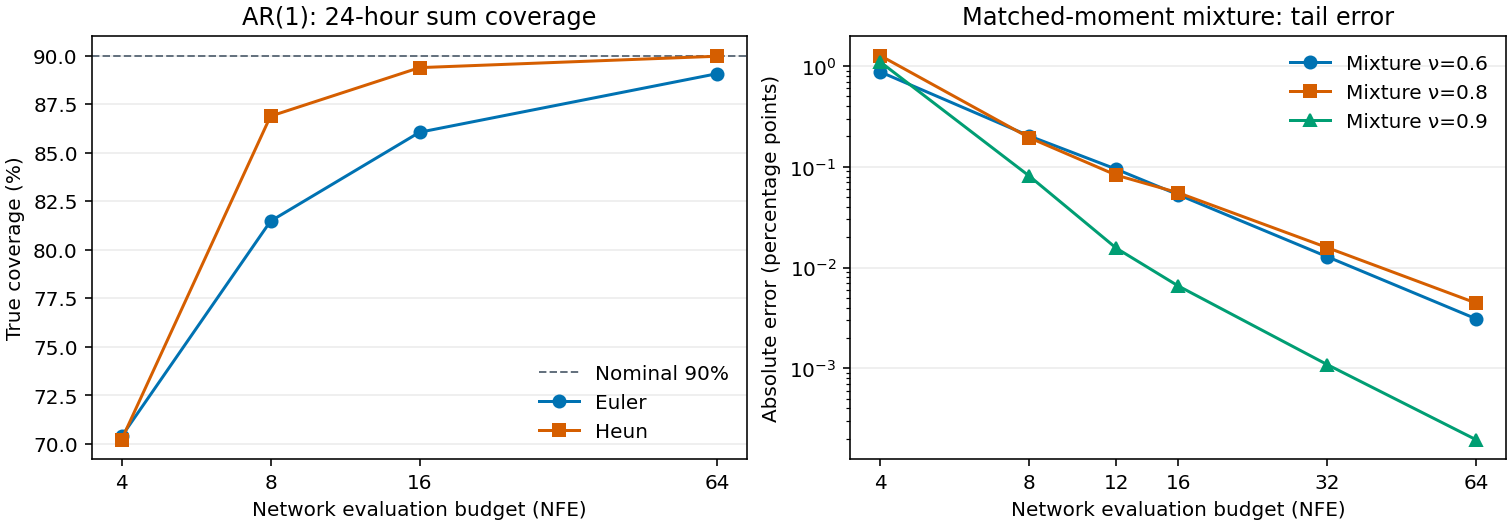

In [3]:
import matplotlib.pyplot as plt

figure, (coverage_ax, tail_ax) = plt.subplots(1, 2, figsize=(10.5, 3.65), layout="constrained")
evaluations, _, euler, heun = np.asarray(gaussian_results).T
coverage_ax.axhline(90, color="#65727f", linestyle="--", linewidth=1, label="Nominal 90%")
coverage_ax.plot(evaluations, 100 * euler, color="#0072B2", marker="o", label="Euler")
coverage_ax.plot(evaluations, 100 * heun, color="#D55E00", marker="s", label="Heun")
coverage_ax.set(title="AR(1): 24-hour sum coverage", xlabel="Network evaluation budget (NFE)", ylabel="True coverage (%)")
coverage_ax.set_xscale("log", base=2)
coverage_ax.set_xticks(evaluations, [str(int(value)) for value in evaluations])
coverage_ax.legend(frameon=False)

mixture_nfe_grid = (4, 8, 12, 16, 32, 64)
for fraction, color, marker in ((0.6, "#0072B2", "o"), (0.8, "#D55E00", "s"), (0.9, "#009E73", "^")):
    tail_errors = [
        100 * abs(mixture_results[fraction, nfe][0] - mixture_results[fraction, nfe][1])
        for nfe in mixture_nfe_grid
    ]
    tail_ax.plot(mixture_nfe_grid, tail_errors, color=color, marker=marker, label=f"Mixture ν={fraction:g}")
tail_ax.set(title="Matched-moment mixture: tail error", xlabel="Network evaluation budget (NFE)", ylabel="Absolute error (percentage points)")
tail_ax.set_xscale("log", base=2)
tail_ax.set_xticks(mixture_nfe_grid, [str(value) for value in mixture_nfe_grid])
tail_ax.set_yscale("log")
tail_ax.legend(frameon=False)
for axis in (coverage_ax, tail_ax):
    axis.grid(axis="y", alpha=0.25)
plt.show()

## 3. 실제 예측에서 사용할 방법

1. 학습한 CFM을 고정한다. 입력 이력 \(c\)마다 같은 초기 난수 \(z\)로 후보 \(N\in\{4,8,12,16\}\)의 경로 \(Y_N(c,z)\)와 고정밀 경로 \(Y_{\mathrm{ref}}(c,z)\)를 만든다. 참조 해상도는 64와 128 NFE, 또는 더 엄격한 적응형 허용오차로 대조해 정한다. 이 작업은 정책 학습 구간에서 미리 수행한다.
2. 일합 \(S(y)=\sum_{h=1}^{24}y_h\)과 최대 3시간 변화폭 \(R(y)=\max_{h\le21}|y_{h+3}-y_h|\)의 오차를 같은 난수끼리 잰다. 학습 구간의 두 척도 \(s_S,s_R\)로 표준화하고 초깃값으로 같은 가중치를 준다. 양의 하한으로 분모를 안정화한다.
   \[
   e_N(c)=\frac12\mathbb E_z\left[\frac{|S(Y_N)-S(Y_{\mathrm{ref}})|}{s_S}
              +\frac{|R(Y_N)-R(Y_{\mathrm{ref}})|}{s_R}\right].
   \]
3. 현재 이력의 변동성과 자기상관, 알려진 달력 변수, 학습 잔차에서 추정한 공분산의 투영 오차를 입력으로 작은 회귀기를 맞춘다. 후보 예산 \(N\)을 함께 입력해 \(\widehat e_N(c)\)를 예측한다. 검증 뒤에는 \(N^*(c)=\arg\min_N[\widehat e_N(c)+\eta N]\)으로 계산을 배분한다. \(\eta\)는 별도 검증 구간에서 평균 예산 8 NFE를 목표로 선택한다. 테스트에서는 실제 평균 NFE와 지연시간을 보고하고 비용 대비 성능 곡선을 비교한다.

**왜 이 목표를 쓰나.** 예상 절댓값이 유한한 스칼라 관측량 \(g\)에 대해, 결합된 두 경로의 차이를 이용해 \(2\mathbb{E}|g(Y_N)-g(Y_\mathrm{ref})|\)로 두 투영 예측의 CRPS 차이를 상계한다. 이는 CRPS의 기대 절대거리 표현과 삼각부등식에서 나온다. 참조 예측의 실측 정확도는 따로 점수로 측정한다. [Proper scoring rules](https://sites.stat.washington.edu/raftery/Research/PDF/Gneiting2007jasa.pdf) · [변환을 이용한 확률예측 평가](https://ascmo.copernicus.org/articles/11/23/2025/index.html)

**검증할 가설.** 같은 비용에서 일합·급변을 목표로 학습한 예산 배분이 전체 경로의 평균 유클리드 오차를 목표로 학습한 배분을 이기는지 본다. 공분산에 관한 특성 없이 학습한 버전도 비교해 분석 결과가 배분 성능에 기여하는지 검증한다.

## 4. 비교 실험과 사전 판정

| 단계 | 고정할 조건과 비교군 | 확인할 결과 |
|---|---|---|
| 합성 벡터장 | AR(1)에서 \(\rho\)를 0, 0.5, 0.8로 바꾸고 독립·정합·불일치 GP prior를 비교한다. 분산과 평균을 맞춘 정규·혼합 분포의 참분포를 사용한다. | 공식과 수치 적분의 일치, 낮은 NFE의 구간 과소포함, 투영 방향과 꼬리 난이도. |
| 학습 오차 | 작은 CFM 하나를 학습하고 같은 체크포인트의 Euler, Heun, 가우시안 참조 솔버 및 고정밀 참조를 대조한다. | 같은 초기 난수에서 저비용 경로와 고정밀 경로의 차이는 적분의 영향이다. 고정밀 경로와 합성 참분포의 차이는 학습된 모형의 오차를 드러낸다. |
| 예산 배분 | 고정 8 NFE, 같은 NFE 빈도의 무작위 배분, 동일 회귀기·특성을 쓰는 전체 경로 오차 기반 배분, 제안한 일합·급변 기반 배분을 비교한다. 가장 강한 재현 가능한 고정 솔버와 FlowBudget 계열 비교를 추가한다. | 같은 예산에서 목표 통계량의 손실이 안정적으로 낮아지는지, 지연시간을 포함해 이점이 유지되는지. |
| 공개 데이터 | TSFlow가 쓰는 시간 단위 Solar, Electricity, Traffic에서 24시간 예측·168시간 이력을 시작점으로 사용한다. 가능하면 별도 공개 장기 데이터 또는 fps-bench 공통 과제로 확장한다. | 태양광에 집중한 결과가 다른 도메인이나 계절에서도 반복되는지. [TSFlow 데이터](https://proceedings.iclr.cc/paper_files/paper/2025/file/ee1a1ecc92f35702b5c29dad3dc909ea-Paper-Conference.pdf) · [PathFM의 평가 과제](https://arxiv.org/abs/2610.22358) |

- **분할.** 데이터 버전과 실제 기준 날짜를 기록한다. 초기안은 시간순 60%로 CFM 학습, 다음 10%로 배분기 적합, 다음 10%로 예산과 설정 결정, 마지막 20%로 잠금 테스트다. 각 예측의 미래 구간은 해당 분할 안에 두고, 원점은 24시간마다 둔다. 정규화와 사건 임계치는 학습 자료에서만 정한다. 공개 벤치마크와 순위를 비교할 때는 같은 공식 분할과 시점에서 다시 평가한다.
- **주 지표.** 24시간 합계의 CRPS를 훈련 구간 척도로 정규화하고 데이터셋을 같은 가중치로 평균한다. 예측 경로마다 먼저 합을 낸 뒤 한 번 채점한다.
- **보조 지표.** 학습 구간에서 정한 상위 10% 급변 기준의 Brier 점수, 90% 일합 구간의 포함률과 폭, 시간별 CRPS, lag별 variogram score(1·3·6·12시간)를 보고한다. 샘플 수는 비교마다 256개로 맞춘다. 같은 체크포인트 비교에서 초기 난수를 공유한다. [Variogram score](https://repository.library.noaa.gov/view/noaa/22327)
- **비용과 추론.** 본 실험은 학습 시드 5개를 사용한다. 같은 날짜의 시리즈를 함께 묶은 paired time-block bootstrap으로 차이의 95% 구간을 구한다. 시작 블록은 7일로 두고 블록 길이 민감도를 확인한다. 평균 NFE와 함께 동일 장비와 배치 정책으로 예열 후 p50·p95 지연시간, 최고 메모리, 배분기 적합 비용을 기록한다.
- **강한 비교군.** 전체 경로를 생성하는 공개 기준으로 독립·GP prior CFM과 학습 잔차를 사용한 Gaussian copula를 포함한다. AREX·FlowBudget의 가장 가까운 재현 가능한 변형과 같은 체크포인트에서 비교한다. PathFM은 사용할 수 있는 모델과 같은 데이터 조건이 확보될 때 공통 과제에서 실제 지연시간과 경로 점수를 비교한다. [Gaussian-copula baseline](https://openreview.net/pdf?id=ZFwFB4MEu2)
- **가설을 버리는 경우.** 높은 NFE에서도 합성 참분포와 큰 차이가 남으면 적분에 예산을 더 쓰는 효과와 모델 학습 오차를 따로 진단한다. 실측에서 고정 솔버 또는 전체 경로 기준 배분과의 차이가 반복되지 않거나 지연시간을 포함하면 이득이 사라질 경우, 예산 배분의 개선 주장을 보류한다. 가우시안 합성 결과는 수치 검산의 증거로 해석한다.

**첫 실험의 제출물**　공분산 공식 검산과 같은 예산의 오라클 표는 이 노트북에서 재실행된다. 다음 랩미팅에서는 학습한 CFM 체크포인트 하나에 고정·무작위·전체 경로·일합/급변 배분을 적용한 비용 대비 점수 표를 목표로 삼는다.